Import libraries


In [21]:
import pandas as pd
import numpy as np
import nltk
import re
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


Download dataset

In [22]:
nltk.download("movie_reviews")

from nltk.corpus import movie_reviews

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


Inspect the dataset

In [23]:
print("Total reviews:", len(movie_reviews.fileids()))

print("First review:")
print(movie_reviews.raw(movie_reviews.fileids()[0])[:500])

Total reviews: 2000
First review:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt


Convert the dataset into pandas dataframe

In [24]:
reviews = []

for fileid in movie_reviews.fileids():
    text = movie_reviews.raw(fileid)
    sentiment = movie_reviews.categories(fileid)[0]

    reviews.append({
        "text": text,
        "sentiment": sentiment
    })

df = pd.DataFrame(reviews)

print(df.head())

                                                text sentiment
0  plot : two teen couples go to a church party ,...       neg
1  the happy bastard's quick movie review \ndamn ...       neg
2  it is movies like these that make a jaded movi...       neg
3   " quest for camelot " is warner bros . ' firs...       neg
4  synopsis : a mentally unstable man undergoing ...       neg


Explore the dataset

In [25]:
print("Dataset shape:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (2000, 2)

Sentiment distribution:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Missing values:
text         0
sentiment    0
dtype: int64


Text preprocessing


In [26]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [27]:
df["clean_text"] = df["text"].apply(clean_text)

print(df[["text", "clean_text"]].head())

                                                text  \
0  plot : two teen couples go to a church party ,...   
1  the happy bastard's quick movie review \ndamn ...   
2  it is movies like these that make a jaded movi...   
3   " quest for camelot " is warner bros . ' firs...   
4  synopsis : a mentally unstable man undergoing ...   

                                          clean_text  
0  plot two teen couples go to a church party dri...  
1  the happy bastard's quick movie review damn th...  
2  it is movies like these that make a jaded movi...  
3  quest for camelot is warner bros ' first featu...  
4  synopsis a mentally unstable man undergoing ps...  


Splitting dataset into training and testing dataset

In [28]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training reviews: 1600
Testing reviews: 400

Training sentiment distribution:
sentiment
pos    800
neg    800
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
neg    200
pos    200
Name: count, dtype: int64


TF-IDF – Converting text into numbers

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [31]:
vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

In [32]:
X_train_tfidf = vectorizer.fit_transform(X_train)

In [33]:
X_test_tfidf = vectorizer.transform(X_test)

In [34]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1600, 20000)
Testing TF-IDF shape: (400, 20000)


Train the machine learning model

In [35]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)
print("Model training completed!")

Model training completed!


Make prediction and evaluate model

In [36]:
y_pred = model.predict(X_test_tfidf)
print("First 10 predictions:")
print(y_pred[:10])


First 10 predictions:
['neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'neg' 'neg' 'neg' 'pos']


In [37]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

print(comparison)

  Actual Predicted
0    neg       neg
1    neg       neg
2    pos       pos
3    neg       pos
4    neg       neg
5    pos       pos
6    pos       neg
7    neg       neg
8    neg       neg
9    pos       pos


Calculate accuracy

In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 83.25 %


calculate precision , recall , f1 score

In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         neg       0.86      0.80      0.83       200
         pos       0.81      0.86      0.84       200

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



Create confusion matrix

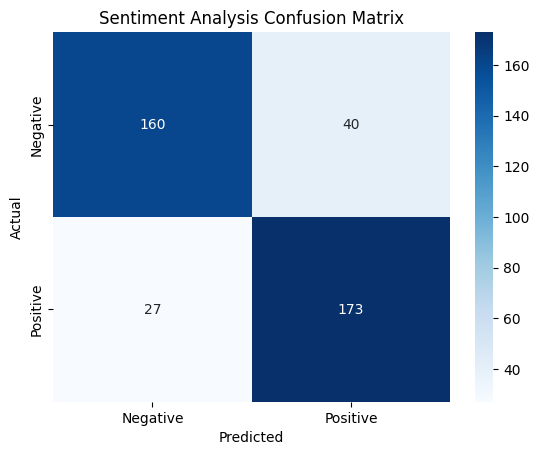

In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=["neg", "pos"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sentiment Analysis Confusion Matrix")
plt.show()

In [41]:
def predict_sentiment(text):
    cleaned = clean_text(text)

    transformed = vectorizer.transform([cleaned])

    prediction = model.predict(transformed)[0]

    probability = model.predict_proba(transformed)[0]

    confidence = max(probability) * 100

    print("Review:", text)
    print("Predicted sentiment:", prediction)
    print("Model confidence:", round(confidence, 2), "%")

In [42]:
predict_sentiment("This movie was absolutely wonderful. I loved every minute of it!")

predict_sentiment("This was a terrible movie. I wasted my time watching it.")

predict_sentiment("The movie was okay, but the story was not very interesting.")


Review: This movie was absolutely wonderful. I loved every minute of it!
Predicted sentiment: neg
Model confidence: 70.77 %
Review: This was a terrible movie. I wasted my time watching it.
Predicted sentiment: neg
Model confidence: 81.72 %
Review: The movie was okay, but the story was not very interesting.
Predicted sentiment: neg
Model confidence: 64.26 %


In [43]:
test_text = "This movie was absolutely wonderful. I loved every minute of it!"

cleaned = clean_text(test_text)

print("Cleaned text:")
print(cleaned)

print("\nPredicted probabilities:")

probabilities = model.predict_proba(
    vectorizer.transform([cleaned])
)[0]

for sentiment, probability in zip(model.classes_, probabilities):
    print(sentiment, ":", round(probability * 100, 2), "%")

Cleaned text:
this movie was absolutely wonderful i loved every minute of it

Predicted probabilities:
neg : 70.77 %
pos : 29.23 %


In [44]:
feature_names = vectorizer.get_feature_names_out()

coefficients = model.coef_[0]

word_importance = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients
})

positive_words = word_importance.sort_values(
    by="coefficient", ascending=False
).head(15)

negative_words = word_importance.sort_values(
    by="coefficient", ascending=True
).head(15)

print("Top positive words:")
print(positive_words)

print("\nTop negative words:")
print(negative_words)


Top positive words:
           word  coefficient
684         and     2.414710
8472         is     1.453024
16160       the     1.254397
1430         as     1.252670
6752      great     1.152350
18652      very     1.057524
9741       life     0.959677
486        also     0.903271
11559        of     0.901863
18827       war     0.896717
19077      well     0.857194
16235  the best     0.826814
18238    truman     0.822078
7535        his     0.820439
11005     mulan     0.793132

Top negative words:
            word  coefficient
1759         bad    -2.236824
19744      worst    -1.257312
7089        have    -1.244801
17665         to    -1.236295
12755       plot    -1.185347
10861      movie    -1.122178
11293         no    -1.067823
12045       only    -1.055614
2354      boring    -1.005782
11449    nothing    -0.996810
14264     script    -0.964426
17406       this    -0.935245
19406        why    -0.914233
6998       harry    -0.910482
17116  the worst    -0.888224


In [46]:
words_to_check = [
    "wonderful",
    "loved",
    "excellent",
    "great",
    "terrible",
    "boring",
    "bad",
    "worst"
]

for word in words_to_check:
    result = word_importance[
        word_importance["word"] == word
    ]

    if not result.empty:
        print(word, ":", round(result["coefficient"].iloc[0], 3))
    else:
        print(word, ": Not found in vocabulary")

wonderful : 0.447
loved : 0.256
excellent : 0.754
great : 1.152
terrible : -0.609
boring : -1.006
bad : -2.237
worst : -1.257


In [47]:
import joblib

joblib.dump(model, "sentiment_model.pkl")

joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [48]:
from google.colab import files

files.download("sentiment_model.pkl")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>